# SRGAN-TV: mejora de un video de la TV peruana (2000-2010)

**Caso 1.** Se toma **un solo video antiguo** de 1 a 2 minutos y se mejora su calidad con un SRGAN
(PyTorch, GPU T4 de Colab).

**Cómo usarlo:** *Entorno de ejecución → Cambiar tipo → GPU (T4)*, y luego *Ejecutar todo*.
Solo editas la celda de **Configuración**.

| Parte | Qué contiene |
|---|---|
| 1. Video | descarga desde Drive (gdown), recorte a 1-2 min, desentrelazado |
| 2. Datos | pares LR/HR creados a partir del propio video |
| 3. **Script de entrenamiento** | SRResNet (fase 1) + SRGAN (fase 2), con **tiempos y pesos** guardados |
| 4. **Script de resultados** | video mejorado, comparación y tabla "antes → después" |
| 5. Presentación | resumen de cambios y mejoras para el modelo |

**Idea clave (autosupervisado):** de un video antiguo no existe una versión HD. Por eso los frames del video se usan
como imagen *HR* y se **degradan aún más** para crear la *LR*. La red aprende a revertir esa degradación y luego se
aplica a los frames originales.

In [1]:
!pip -q install -U gdown

## 0. Configuración (edita solo esta celda)

In [2]:
# ============================== CONFIGURACIÓN ==============================
# --- Video -------------------------------------------------------------------
VIDEO_MODE   = "gdown"                      # "gdown" | "drive" | "upload" | "path"
# "gdown": descarga la carpeta compartida (debe estar como "Cualquier persona con el enlace - Lector")
VIDEO_DRIVE_URL = "https://drive.google.com/drive/folders/1mPY3G-2Vl25GMQTcP62aZW4UHCInvo4D?usp=sharing"
# "drive": monta tu Drive; "path": ruta local
VIDEO_PATH   = "/content/drive/MyDrive/PC3_SRGAN/clip_especial_humor_congreso_240p.mp4"
CLIP_START   = 0                            # segundo de inicio del recorte (0 si el video ya es el clip)
CLIP_DURATION = None                        # None: todo si dura <=120 s; si no, 90 s

# --- Modelo / entrenamiento ----------------------------------------------------
SCALE   = 2        # 2 (240p -> 480p) o 4
PATCH   = 96       # tamaño del parche HR (la LR mide PATCH/SCALE)
BATCH   = 16
ITERS_PRE = 3000   # fase 1: SRResNet (solo L1)
ITERS_GAN = 6000   # fase 2: SRGAN
LR_PRE, LR_GAN = 2e-4, 1e-4
W_PIX, W_PERC, W_ADV, W_COLOR = 1e-2, 1.0, 5e-3, 0.1
CH, N_BLOCKS = 64, 16

# --- Datos extra opcionales (mejoran el detalle) ----------------------------------
USE_DIV2K = False  # True: descarga DIV2K (~3.5 GB) y lo mezcla con los frames del video
P_EXTRA   = 0.5    # probabilidad de usar una imagen de DIV2K en cada muestra
MAX_TRAIN_FRAMES = 1500

# --- Evidencias y sistema -------------------------------------------------------
VAL_EVERY, SAMPLE_EVERY, LOG_EVERY = 500, 500, 25
NUM_WORKERS = 2
OUT  = "/content/srgan_tv"                  # carpeta con todas las evidencias
SAVE_TO_DRIVE = False                       # copiar evidencias a Google Drive al final
DRIVE_DIR = "/content/drive/MyDrive/PC3_SRGAN"
SEED = 42

In [3]:
import os, math, time, json, shutil, subprocess, hashlib, platform, random
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils import spectral_norm
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = dev.type == "cuda"
os.makedirs(OUT, exist_ok=True)
HW = {"python": platform.python_version(), "torch": torch.__version__, "device": str(dev)}
if dev.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    HW.update(gpu=p.name, gpu_mem_gb=round(p.total_memory / 1e9, 1), cuda=torch.version.cuda)
else:
    print("AVISO: no hay GPU. Activa  Entorno de ejecución > Cambiar tipo > GPU")
print(HW)

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'device': 'cuda', 'gpu': 'Tesla T4', 'gpu_mem_gb': 15.6, 'cuda': '13.0'}


## 1. Video: carga desde Drive, recorte y desentrelazado

Requisitos del video: TV peruana 2000-2010, **1 a 2 minutos**, resolución nativa (sin escalar con IA),
con rostros visibles y con audio.

El video se descarga de la **carpeta compartida de Google Drive** (`VIDEO_MODE = "gdown"`, enlace en `VIDEO_DRIVE_URL`;
la carpeta debe estar como *Cualquier persona con el enlace - Lector*). Alternativas: `"drive"` (montar tu Drive), `"upload"` o `"path"`. La descarga del video se hizo aparte con `descargar_clip.py`.

In [4]:
def probe(path):
    out = subprocess.check_output(["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries",
        "stream=width,height,r_frame_rate,field_order,bit_rate,codec_name:format=duration,size,bit_rate",
        "-of", "json", path])
    j = json.loads(out); s = j["streams"][0]; f = j["format"]
    n, d = s["r_frame_rate"].split("/")
    return {"w": int(s["width"]), "h": int(s["height"]), "fps": float(n) / float(d),
            "fps_str": s["r_frame_rate"], "field_order": s.get("field_order", "unknown"),
            "codec": s.get("codec_name"), "duration": float(f["duration"]),
            "size_mb": round(int(f.get("size", 0)) / 1e6, 2),
            "bitrate_kbps": round(int(s.get("bit_rate") or f.get("bit_rate") or 0) / 1000)}

RAW = f"{OUT}/video_original_descargado.mp4"
if VIDEO_MODE == "gdown":
    import gdown
    dl = f"{OUT}/descarga_drive"
    gdown.download_folder(VIDEO_DRIVE_URL, output=dl, quiet=False, use_cookies=False)
    vids = sorted(p for p in Path(dl).rglob("*") if p.suffix.lower() in (".mp4", ".mkv", ".avi", ".mov", ".webm"))
    assert vids, "No se encontró ningún video en la carpeta de Drive (¿está compartida como 'Cualquier persona con el enlace'?)"
    print("Videos encontrados:", [v.name for v in vids]); shutil.copy(vids[0], RAW)
elif VIDEO_MODE == "upload":
    from google.colab import files
    up = files.upload(); shutil.move(list(up)[0], RAW)
elif VIDEO_MODE == "drive":
    from google.colab import drive
    drive.mount("/content/drive"); shutil.copy(VIDEO_PATH, RAW)
else:
    shutil.copy(VIDEO_PATH, RAW)

INFO_RAW = probe(RAW)
print("Video descargado:", INFO_RAW)

# Recorte a 1-2 min + desentrelazado (solo actúa si el video está marcado como entrelazado)
total = INFO_RAW["duration"] - CLIP_START
dur = CLIP_DURATION or (total if total <= 120 else 90)
CLIP = f"{OUT}/clip_original.mp4"
subprocess.run(["ffmpeg", "-y", "-v", "error", "-ss", str(CLIP_START), "-i", RAW, "-t", str(dur),
                "-vf", "bwdif=mode=send_frame:parity=auto:deint=interlaced",
                "-c:v", "libx264", "-crf", "12", "-preset", "fast", "-pix_fmt", "yuv420p",
                "-c:a", "aac", "-b:a", "160k", CLIP], check=True)
INFO = probe(CLIP)
print("Clip de trabajo:", INFO)
assert 55 <= INFO["duration"] <= 125, f"El clip dura {INFO['duration']:.0f}s: debe estar entre 60 y 120 s"

Retrieving folder contents


Processing file 1xtdZvpAvYQROvHUh-2Lb0ypVvOFJLadH clip_especial_humor_congreso_240p.mp4


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1xtdZvpAvYQROvHUh-2Lb0ypVvOFJLadH
To: /content/srgan_tv/descarga_drive/clip_especial_humor_congreso_240p.mp4
100%|██████████| 4.53M/4.53M [00:00<00:00, 16.7MB/s]
Download completed


Videos encontrados: ['clip_especial_humor_congreso_240p.mp4']
Video descargado: {'w': 320, 'h': 240, 'fps': 30.0, 'fps_str': '30/1', 'field_order': 'progressive', 'codec': 'h264', 'duration': 65.0, 'size_mb': 4.53, 'bitrate_kbps': 388}
Clip de trabajo: {'w': 320, 'h': 240, 'fps': 30.0, 'fps_str': '30/1', 'field_order': 'progressive', 'codec': 'h264', 'duration': 65.0, 'size_mb': 4.54, 'bitrate_kbps': 390}


1950 frames en el clip | usados: 975 (cada 2) | train 927 / val 48 | tamaño 320x240


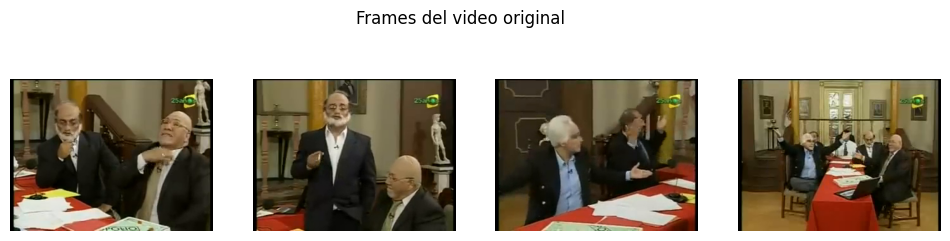

In [5]:
# Carga de frames a RAM (submuestreados para el entrenamiento)
cap = cv2.VideoCapture(CLIP)
n_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
stride = max(1, math.ceil(n_total / MAX_TRAIN_FRAMES))
frames, i = [], 0
while True:
    ok, f = cap.read()
    if not ok: break
    if i % stride == 0: frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    i += 1
cap.release()
n_val = max(4, int(0.05 * len(frames)))
train_frames, val_frames = frames[:-n_val], frames[-n_val:]      # validación = final del clip
H0, W0 = frames[0].shape[:2]
print(f"{n_total} frames en el clip | usados: {len(frames)} (cada {stride}) | "
      f"train {len(train_frames)} / val {len(val_frames)} | tamaño {W0}x{H0}")
plt.figure(figsize=(12, 3))
for k, j in enumerate(np.linspace(0, len(frames) - 1, 4).astype(int)):
    plt.subplot(1, 4, k + 1); plt.imshow(frames[j]); plt.axis("off")
plt.suptitle("Frames del video original"); plt.show()

## 2. Datos: degradación "TV antigua" (LR) a partir de los frames (HR)

**Adaptación principal:** el SRGAN original crea la LR con un simple *bicúbico*. Aquí la LR se genera con una cadena
aleatoria que imita lo que tiene un video de TV de esa época: **desenfoque**, reducción de resolución, **color de baja
resolución** (NTSC/VHS), **ruido analógico** y **doble compresión** (MPEG-2 + YouTube). Así la red aprende a limpiar
justo lo que tiene el video real.

LR: (16, 3, 48, 48)  HR: (16, 3, 96, 96)


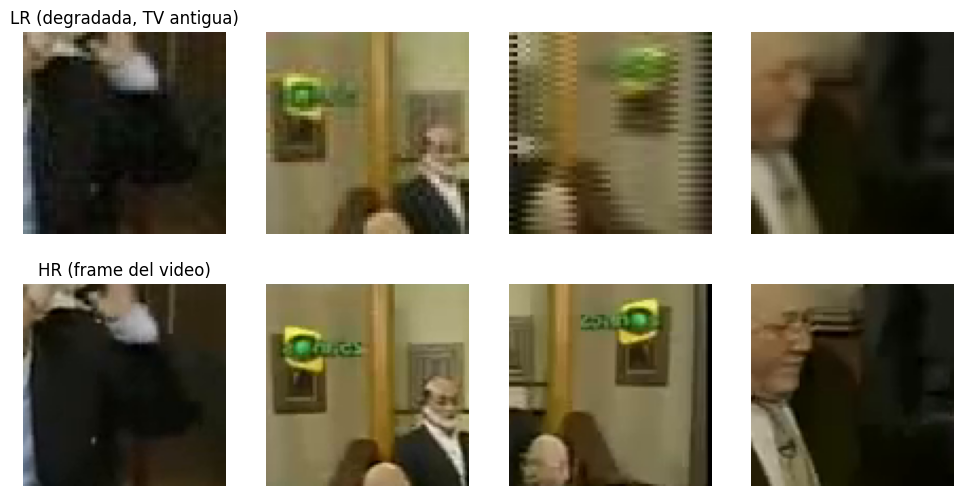

In [6]:
def degrade(hr, scale, rng):
    """hr: HxWx3 float32 [0,1] -> lr (H/scale x W/scale). Cadena aleatoria de degradaciones TV."""
    st = rng.uniform(0.3, 1.0)                                   # intensidad de esta muestra
    h, w = hr.shape[0] // scale, hr.shape[1] // scale
    img = hr
    if rng.random() < 0.9:                                       # 1) desenfoque
        img = cv2.GaussianBlur(img, (0, 0), rng.uniform(0.3, 0.5 + 1.5 * st))
    img = cv2.resize(img, (w, h), interpolation=int(rng.choice([cv2.INTER_AREA, cv2.INTER_LINEAR, cv2.INTER_CUBIC])))
    if rng.random() < 0.7:                                       # 2) croma de baja resolución
        ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb); c = ycc[..., 1:]
        f = int(rng.choice([2, 3, 4]))
        c = cv2.resize(cv2.resize(c, (max(2, w // f), h), interpolation=cv2.INTER_AREA), (w, h), interpolation=cv2.INTER_LINEAR)
        ycc[..., 1:] = c; img = cv2.cvtColor(ycc, cv2.COLOR_YCrCb2RGB)
    if rng.random() < 0.3 * st + 0.1:                            # 3) entrelazado (peinado)
        sh = np.roll(img, int(rng.integers(1, 3)), axis=1); img = img.copy(); img[1::2] = sh[1::2]
    if rng.random() < 0.8:                                       # 4) ruido analógico
        img = img + rng.normal(0, rng.uniform(1, 2 + 8 * st) / 255, img.shape).astype(np.float32)
    img = np.clip(img, 0, 1)
    for _ in range(int(rng.integers(1, 3))):                     # 5) compresión (1-2 veces)
        q = int(rng.integers(int(90 - 50 * st), 95))
        ok, buf = cv2.imencode(".jpg", cv2.cvtColor((img * 255 + .5).astype(np.uint8), cv2.COLOR_RGB2BGR),
                               [cv2.IMWRITE_JPEG_QUALITY, q])
        img = cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB).astype(np.float32) / 255
    return img

def to_t(a): return torch.from_numpy(np.ascontiguousarray(a.transpose(2, 0, 1)))

EXTRA = []
if USE_DIV2K:
    if not os.path.exists("/content/DIV2K_train_HR"):
        subprocess.run("wget -q http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip -O /content/div2k.zip "
                       "&& unzip -q /content/div2k.zip -d /content", shell=True, check=True)
    EXTRA = sorted(str(p) for p in Path("/content/DIV2K_train_HR").glob("*.png"))
    print("DIV2K:", len(EXTRA), "imágenes")

class VideoSRDataset(Dataset):
    def __init__(self, frames, scale, patch, extra=(), p_extra=0.0, length=10**6):
        self.frames, self.scale, self.patch, self.extra, self.p_extra, self.length = frames, scale, patch, list(extra), p_extra, length
    def __len__(self): return self.length
    def __getitem__(self, _):
        rng = np.random.default_rng()
        if self.extra and rng.random() < self.p_extra:
            img = cv2.cvtColor(cv2.imread(self.extra[rng.integers(len(self.extra))]), cv2.COLOR_BGR2RGB)
        else:
            img = self.frames[rng.integers(len(self.frames))]
        H, W = img.shape[:2]
        ps = min(self.patch, H, W); ps -= ps % self.scale
        y, x = int(rng.integers(0, H - ps + 1)), int(rng.integers(0, W - ps + 1))
        hr = img[y:y + ps, x:x + ps].astype(np.float32) / 255
        if rng.random() < 0.5: hr = hr[:, ::-1]
        hr = np.ascontiguousarray(hr)
        return to_t(degrade(hr, self.scale, rng)), to_t(hr)

train_ds = VideoSRDataset(train_frames, SCALE, PATCH, EXTRA, P_EXTRA)
train_dl = DataLoader(train_ds, BATCH, num_workers=NUM_WORKERS, drop_last=True,
                      persistent_workers=NUM_WORKERS > 0, pin_memory=AMP)

# Validación fija (misma semilla): permite comparar PSNR/SSIM entre iteraciones
vps = min(128, H0, W0); vps -= vps % SCALE
val_pairs = []
for k in range(len(val_frames) * 2):
    fr = val_frames[k % len(val_frames)]
    y, x = (fr.shape[0] - vps) // 2, (fr.shape[1] - vps) // 2 + 8 * (k // len(val_frames))
    x = min(x, fr.shape[1] - vps)
    hr = fr[y:y + vps, x:x + vps].astype(np.float32) / 255
    val_pairs.append((to_t(degrade(hr, SCALE, np.random.default_rng(1000 + k))), to_t(hr)))
VAL_LR = torch.stack([a for a, _ in val_pairs]); VAL_HR = torch.stack([b for _, b in val_pairs])

lr_b, hr_b = next(iter(train_dl))
print("LR:", tuple(lr_b.shape), " HR:", tuple(hr_b.shape))
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for k in range(4):
    ax[0, k].imshow(F.interpolate(lr_b[k:k + 1], scale_factor=SCALE, mode="nearest")[0].permute(1, 2, 0).clamp(0, 1)); ax[0, k].axis("off")
    ax[1, k].imshow(hr_b[k].permute(1, 2, 0)); ax[1, k].axis("off")
ax[0, 0].set_title("LR (degradada, TV antigua)"); ax[1, 0].set_title("HR (frame del video)")
plt.show()

## 3. SCRIPT DE ENTRENAMIENTO

### Modelo y cambios respecto al SRGAN original (Ledig et al., 2017)
| Original | Aquí | Motivo |
|---|---|---|
| LR por bicúbico | **Cadena de degradación de TV antigua** | El video real no tiene degradación bicúbica |
| BatchNorm en el generador | **Sin BatchNorm** + escalado residual 0.2 | Menos artefactos de color, entrenamiento estable |
| Salida directa | **Aprendizaje residual sobre el bicúbico** | La red solo aprende el detalle que falta |
| MSE de píxel | **L1** | Menos borroso y robusto al ruido |
| VGG tras ReLU | **VGG conv5_4 antes de ReLU** | Mejor supervisión de textura |
| GAN estándar | **GAN relativista (RaGAN)** + **Spectral Norm** en D | Gradientes más estables |
| — | **Pérdida de color** (baja frecuencia) | La GAN no cambia los tonos del programa |
| Entrenar G+D directo | **Fase 1** SRResNet (L1) y luego **Fase 2** SRGAN | Arranque estable |
| MSE para escala fija 4× | Escala configurable (2× o 4×) y entrada de cualquier tamaño | El video es SD pequeño |

In [7]:
class ResBlock(nn.Module):
    def __init__(s, ch, rs=0.2):
        super().__init__(); s.b = nn.Sequential(nn.Conv2d(ch, ch, 3, 1, 1), nn.PReLU(ch), nn.Conv2d(ch, ch, 3, 1, 1)); s.rs = rs
    def forward(s, x): return x + s.rs * s.b(x)

class Generator(nn.Module):
    def __init__(s, scale=2, ch=64, n_blocks=16):
        super().__init__(); s.scale = scale
        s.head = nn.Sequential(nn.Conv2d(3, ch, 9, 1, 4), nn.PReLU(ch))
        s.body = nn.Sequential(*[ResBlock(ch) for _ in range(n_blocks)])
        s.body_tail = nn.Conv2d(ch, ch, 3, 1, 1)
        ups = []
        for _ in range(int(math.log2(scale))):
            ups += [nn.Conv2d(ch, ch * 4, 3, 1, 1), nn.PixelShuffle(2), nn.PReLU(ch)]
        s.up = nn.Sequential(*ups)
        s.tail = nn.Conv2d(ch, 3, 9, 1, 4)
        nn.init.zeros_(s.tail.bias); s.tail.weight.data.mul_(0.1)      # arranca ~ bicúbico
    def forward(s, x):
        f = s.head(x); f = f + s.body_tail(s.body(f))
        return s.tail(s.up(f)) + F.interpolate(x, scale_factor=s.scale, mode="bicubic", align_corners=False)

class Discriminator(nn.Module):
    def __init__(s, ch=64):
        super().__init__(); sn = spectral_norm
        def blk(i, o, st): return [sn(nn.Conv2d(i, o, 3, st, 1)), nn.LeakyReLU(0.2, True)]
        s.f = nn.Sequential(sn(nn.Conv2d(3, ch, 3, 1, 1)), nn.LeakyReLU(0.2, True), *blk(ch, ch, 2),
                            *blk(ch, ch * 2, 1), *blk(ch * 2, ch * 2, 2), *blk(ch * 2, ch * 4, 1), *blk(ch * 4, ch * 4, 2),
                            *blk(ch * 4, ch * 8, 1), *blk(ch * 8, ch * 8, 2))
        s.pool = nn.AdaptiveAvgPool2d(4)
        s.c = nn.Sequential(nn.Flatten(), sn(nn.Linear(ch * 8 * 16, 1024)), nn.LeakyReLU(0.2, True), sn(nn.Linear(1024, 1)))
    def forward(s, x): return s.c(s.pool(s.f(x)))

class VGGFeat(nn.Module):
    def __init__(s):
        super().__init__()
        from torchvision.models import vgg19, VGG19_Weights
        s.v = vgg19(weights=VGG19_Weights.IMAGENET1K_V1).features[:35].eval().requires_grad_(False)   # conv5_4 sin ReLU
        s.register_buffer("m", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        s.register_buffer("sd", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(s, x): return s.v((x - s.m) / s.sd)

def n_params(m): return sum(p.numel() for p in m.parameters())

G = Generator(SCALE, CH, N_BLOCKS).to(dev); D = Discriminator().to(dev)
print(f"Generador: {n_params(G)/1e6:.2f} M parámetros | Discriminador: {n_params(D)/1e6:.2f} M")

# ---- pérdidas
def ragan_d(d_real, d_fake):
    r, f = d_real - d_fake.mean(), d_fake - d_real.mean()
    return 0.5 * (F.binary_cross_entropy_with_logits(r, torch.ones_like(r)) + F.binary_cross_entropy_with_logits(f, torch.zeros_like(f)))
def ragan_g(d_real, d_fake):
    r, f = d_real - d_fake.mean(), d_fake - d_real.mean()
    return 0.5 * (F.binary_cross_entropy_with_logits(r, torch.zeros_like(r)) + F.binary_cross_entropy_with_logits(f, torch.ones_like(f)))
def color_loss(sr, hr, k=8): return F.l1_loss(F.avg_pool2d(sr, k), F.avg_pool2d(hr, k))

# ---- métricas (canal Y)
def rgb2y(x): return (x * x.new_tensor([65.481, 128.553, 24.966]).view(1, 3, 1, 1)).sum(1, keepdim=True).add(16) / 255
def psnr_y(a, b, bd=4):
    a, b = rgb2y(a.clamp(0, 1))[..., bd:-bd, bd:-bd], rgb2y(b)[..., bd:-bd, bd:-bd]
    return (10 * torch.log10(1 / ((a - b) ** 2).mean((1, 2, 3)).clamp_min(1e-10)))
def ssim_y(a, b, bd=4):
    x, y = rgb2y(a.clamp(0, 1))[..., bd:-bd, bd:-bd], rgb2y(b)[..., bd:-bd, bd:-bd]
    g = torch.arange(11, dtype=torch.float32, device=x.device) - 5; g = torch.exp(-g ** 2 / 4.5); g = g / g.sum()
    w = (g[:, None] @ g[None]).view(1, 1, 11, 11)
    mx, my = F.conv2d(x, w), F.conv2d(y, w)
    sxx, syy, sxy = F.conv2d(x * x, w) - mx ** 2, F.conv2d(y * y, w) - my ** 2, F.conv2d(x * y, w) - mx * my
    c1, c2 = .01 ** 2, .03 ** 2
    return (((2 * mx * my + c1) * (2 * sxy + c2)) / ((mx ** 2 + my ** 2 + c1) * (sxx + syy + c2))).mean((1, 2, 3))

@torch.no_grad()
def validate():
    G.eval(); lr, hr = VAL_LR.to(dev), VAL_HR.to(dev)
    sr = torch.cat([G(lr[i:i + 8]) for i in range(0, len(lr), 8)]).clamp(0, 1)
    bic = F.interpolate(lr, scale_factor=SCALE, mode="bicubic", align_corners=False).clamp(0, 1)
    G.train()
    return dict(psnr=psnr_y(sr, hr).mean().item(), ssim=ssim_y(sr, hr).mean().item(),
                psnr_bic=psnr_y(bic, hr).mean().item(), ssim_bic=ssim_y(bic, hr).mean().item()), sr.cpu()

def label(img, t, x=0):
    img = np.ascontiguousarray(img).copy(); cv2.rectangle(img, (x, 0), (x + len(t) * 9 + 8, 18), (0, 0, 0), -1)
    cv2.putText(img, t, (x + 4, 13), cv2.FONT_HERSHEY_SIMPLEX, .45, (255, 255, 255), 1, cv2.LINE_AA); return img

def u8(t): return (t.clamp(0, 1).permute(1, 2, 0).numpy() * 255 + .5).astype(np.uint8)

def save_samples(tag, sr):
    rows = []
    for k in range(min(3, len(sr))):
        lr = VAL_LR[k:k + 1]
        tiles = [label(u8(F.interpolate(lr, scale_factor=SCALE, mode="nearest")[0]), "LR (TV)"),
                 label(u8(F.interpolate(lr, scale_factor=SCALE, mode="bicubic", align_corners=False)[0]), "Bicubico"),
                 label(u8(sr[k]), "SRGAN-TV"), label(u8(VAL_HR[k]), "HR")]
        rows.append(np.concatenate(tiles, 1))
    cv2.imwrite(f"{OUT}/samples/{tag}.png", cv2.cvtColor(np.concatenate(rows, 0), cv2.COLOR_RGB2BGR))

Generador: 1.40 M parámetros | Discriminador: 13.08 M


In [8]:
# =============================== ENTRENAMIENTO ===============================
for d in ("samples", "checkpoints", "plots"): os.makedirs(f"{OUT}/{d}", exist_ok=True)
data_it = iter(train_dl)
def batch():
    global data_it
    try: lr, hr = next(data_it)
    except StopIteration: data_it = iter(train_dl); lr, hr = next(data_it)
    return lr.to(dev, non_blocking=True), hr.to(dev, non_blocking=True)

log, vlog = [], []
STATS = {"inicio": datetime.now().isoformat(timespec="seconds"), "hardware": HW, "fases": {}}
def sync():
    if dev.type == "cuda": torch.cuda.synchronize()

# ---------------- FASE 1: SRResNet (solo L1) ----------------
opt_g = torch.optim.Adam(G.parameters(), lr=LR_PRE, betas=(0.9, 0.99))
sc_g = torch.amp.GradScaler("cuda", enabled=AMP)
t0 = time.perf_counter(); G.train()
for it in tqdm(range(1, ITERS_PRE + 1), desc="Fase 1: SRResNet (L1)"):
    if it in (ITERS_PRE // 2, ITERS_PRE * 3 // 4):
        for g in opt_g.param_groups: g["lr"] *= 0.5
    lr, hr = batch()
    with torch.autocast(dev.type, torch.float16, enabled=AMP): sr = G(lr)
    loss = F.l1_loss(sr.float(), hr)
    opt_g.zero_grad(set_to_none=True); sc_g.scale(loss).backward(); sc_g.step(opt_g); sc_g.update()
    if it % LOG_EVERY == 0 or it == 1:
        log.append(dict(iter=it, phase="pre", l_pix=loss.item(), t=time.perf_counter() - t0))
    if it % VAL_EVERY == 0 or it == ITERS_PRE:
        m, sr_v = validate(); vlog.append(dict(iter=it, phase="pre", **m)); save_samples(f"pre_{it:06d}", sr_v)
        tqdm.write(f"[val {it}] PSNR {m['psnr']:.2f} dB (bicúbico {m['psnr_bic']:.2f}) | SSIM {m['ssim']:.4f} ({m['ssim_bic']:.4f})")
sync(); STATS["fases"]["fase1_srresnet"] = {"iteraciones": ITERS_PRE, "segundos": round(time.perf_counter() - t0, 1)}
torch.save({"G": G.state_dict(), "cfg": dict(scale=SCALE, ch=CH, n_blocks=N_BLOCKS)}, f"{OUT}/checkpoints/G_fase1_srresnet.pth")

# ---------------- FASE 2: SRGAN ----------------
vgg = VGGFeat().to(dev)
opt_g = torch.optim.Adam(G.parameters(), lr=LR_GAN, betas=(0.9, 0.99))
opt_d = torch.optim.Adam(D.parameters(), lr=LR_GAN, betas=(0.9, 0.99))
sc_g, sc_d = torch.amp.GradScaler("cuda", enabled=AMP), torch.amp.GradScaler("cuda", enabled=AMP)
t1 = time.perf_counter()
for it in tqdm(range(ITERS_PRE + 1, ITERS_PRE + ITERS_GAN + 1), desc="Fase 2: SRGAN"):
    if it in (ITERS_PRE + ITERS_GAN // 2, ITERS_PRE + ITERS_GAN * 3 // 4):
        for o in (opt_g, opt_d):
            for g in o.param_groups: g["lr"] *= 0.5
    lr, hr = batch()
    # --- Generador
    D.requires_grad_(False)
    with torch.autocast(dev.type, torch.float16, enabled=AMP):
        sr = G(lr); d_fake = D(sr); d_real = D(hr).detach()
        f_sr, f_hr = vgg(sr.clamp(0, 1)), vgg(hr).detach()
    sr, d_fake, d_real = sr.float(), d_fake.float(), d_real.float()
    l_pix, l_perc = F.l1_loss(sr, hr), F.l1_loss(f_sr.float(), f_hr.float())
    l_adv, l_col = ragan_g(d_real, d_fake), color_loss(sr, hr)
    l_g = W_PIX * l_pix + W_PERC * l_perc + W_ADV * l_adv + W_COLOR * l_col
    opt_g.zero_grad(set_to_none=True); sc_g.scale(l_g).backward(); sc_g.step(opt_g); sc_g.update()
    # --- Discriminador
    D.requires_grad_(True)
    with torch.autocast(dev.type, torch.float16, enabled=AMP):
        dr, df = D(hr), D(sr.detach())
    l_d = ragan_d(dr.float(), df.float())
    opt_d.zero_grad(set_to_none=True); sc_d.scale(l_d).backward(); sc_d.step(opt_d); sc_d.update()
    if it % LOG_EVERY == 0 or it == ITERS_PRE + 1:
        log.append(dict(iter=it, phase="gan", l_pix=l_pix.item(), l_perc=l_perc.item(), l_adv=l_adv.item(),
                        l_color=l_col.item(), l_g=l_g.item(), l_d=l_d.item(),
                        d_real=torch.sigmoid(dr.float()).mean().item(), d_fake=torch.sigmoid(df.float()).mean().item(),
                        t=time.perf_counter() - t0))
    if it % VAL_EVERY == 0 or it == ITERS_PRE + ITERS_GAN:
        m, sr_v = validate(); vlog.append(dict(iter=it, phase="gan", **m)); save_samples(f"gan_{it:06d}", sr_v)
        tqdm.write(f"[val {it}] PSNR {m['psnr']:.2f} dB (bicúbico {m['psnr_bic']:.2f}) | SSIM {m['ssim']:.4f} ({m['ssim_bic']:.4f})")
sync()
STATS["fases"]["fase2_srgan"] = {"iteraciones": ITERS_GAN, "segundos": round(time.perf_counter() - t1, 1)}
T_TOTAL = time.perf_counter() - t0

Fase 1: SRResNet (L1):   0%|          | 0/3000 [00:00<?, ?it/s]

[val 500] PSNR 31.70 dB (bicúbico 29.93) | SSIM 0.8889 (0.8354)
[val 1000] PSNR 32.15 dB (bicúbico 29.93) | SSIM 0.8988 (0.8354)
[val 1500] PSNR 32.25 dB (bicúbico 29.93) | SSIM 0.9001 (0.8354)
[val 2000] PSNR 32.62 dB (bicúbico 29.93) | SSIM 0.9074 (0.8354)
[val 2500] PSNR 32.83 dB (bicúbico 29.93) | SSIM 0.9108 (0.8354)
[val 3000] PSNR 32.83 dB (bicúbico 29.93) | SSIM 0.9104 (0.8354)
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:06<00:00, 85.5MB/s]


Fase 2: SRGAN:   0%|          | 0/6000 [00:00<?, ?it/s]

[val 3500] PSNR 31.82 dB (bicúbico 29.93) | SSIM 0.8917 (0.8354)
[val 4000] PSNR 31.56 dB (bicúbico 29.93) | SSIM 0.8891 (0.8354)
[val 4500] PSNR 31.47 dB (bicúbico 29.93) | SSIM 0.8861 (0.8354)
[val 5000] PSNR 31.60 dB (bicúbico 29.93) | SSIM 0.8879 (0.8354)
[val 5500] PSNR 31.50 dB (bicúbico 29.93) | SSIM 0.8843 (0.8354)
[val 6000] PSNR 31.31 dB (bicúbico 29.93) | SSIM 0.8789 (0.8354)
[val 6500] PSNR 31.44 dB (bicúbico 29.93) | SSIM 0.8837 (0.8354)
[val 7000] PSNR 31.59 dB (bicúbico 29.93) | SSIM 0.8877 (0.8354)
[val 7500] PSNR 31.44 dB (bicúbico 29.93) | SSIM 0.8862 (0.8354)
[val 8000] PSNR 31.49 dB (bicúbico 29.93) | SSIM 0.8885 (0.8354)
[val 8500] PSNR 31.49 dB (bicúbico 29.93) | SSIM 0.8877 (0.8354)
[val 9000] PSNR 31.34 dB (bicúbico 29.93) | SSIM 0.8844 (0.8354)


### Pesos obtenidos y tiempo de entrenamiento (evidencia)

In [9]:
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()

def hms(s): s = int(round(s)); return f"{s // 3600}h {s % 3600 // 60:02d}m {s % 60:02d}s"

cfg = dict(scale=SCALE, ch=CH, n_blocks=N_BLOCKS)
torch.save({"G": G.state_dict(), "cfg": cfg}, f"{OUT}/checkpoints/G_final_srgan.pth")
torch.save({"D": D.state_dict()}, f"{OUT}/checkpoints/D_final.pth")
pd.DataFrame(log).to_csv(f"{OUT}/train_log.csv", index=False)
pd.DataFrame(vlog).to_csv(f"{OUT}/val_log.csv", index=False)

weights = [{"archivo": p.name, "MB": round(p.stat().st_size / 1e6, 2), "sha256": sha256(p)}
           for p in sorted(Path(f"{OUT}/checkpoints").glob("*.pth"))]
STATS.update(fin=datetime.now().isoformat(timespec="seconds"), tiempo_total_segundos=round(T_TOTAL, 1),
             tiempo_total=hms(T_TOTAL), parametros_generador=n_params(G), parametros_discriminador=n_params(D),
             val_final=vlog[-1] if vlog else None, pesos=weights,
             config={k: globals()[k] for k in ("SCALE", "PATCH", "BATCH", "ITERS_PRE", "ITERS_GAN", "LR_PRE", "LR_GAN",
                                              "W_PIX", "W_PERC", "W_ADV", "W_COLOR", "CH", "N_BLOCKS", "USE_DIV2K")},
             video={"original": INFO_RAW, "clip": INFO, "frames_entrenamiento": len(train_frames)})
json.dump(STATS, open(f"{OUT}/training_report.json", "w"), indent=2, ensure_ascii=False)

print("=" * 64); print("PESOS OBTENIDOS Y TIEMPO DE ENTRENAMIENTO"); print("=" * 64)
print(f"Tiempo total        : {hms(T_TOTAL)}")
for k, v in STATS["fases"].items(): print(f"  {k:<18}: {hms(v['segundos'])}  ({v['iteraciones']} iteraciones)")
print(f"Generador           : {n_params(G):,} parámetros")
print(f"Discriminador       : {n_params(D):,} parámetros")
print("Archivos de pesos:")
for w in weights: print(f"  {w['archivo']:<26} {w['MB']:>7.2f} MB  sha256={w['sha256'][:16]}...")
if vlog: print(f"PSNR final (val)    : {vlog[-1]['psnr']:.2f} dB vs bicúbico {vlog[-1]['psnr_bic']:.2f} dB")

PESOS OBTENIDOS Y TIEMPO DE ENTRENAMIENTO
Tiempo total        : 0h 19m 11s
  fase1_srresnet    : 0h 03m 11s  (3000 iteraciones)
  fase2_srgan       : 0h 15m 50s  (6000 iteraciones)
Generador           : 1,398,659 parámetros
Discriminador       : 13,076,033 parámetros
Archivos de pesos:
  D_final.pth                  52.42 MB  sha256=7fae30e110006f8d...
  G_fase1_srresnet.pth          5.63 MB  sha256=77e692ef7da1c674...
  G_final_srgan.pth             5.63 MB  sha256=eb02feeeee4c6113...
PSNR final (val)    : 31.34 dB vs bicúbico 29.93 dB


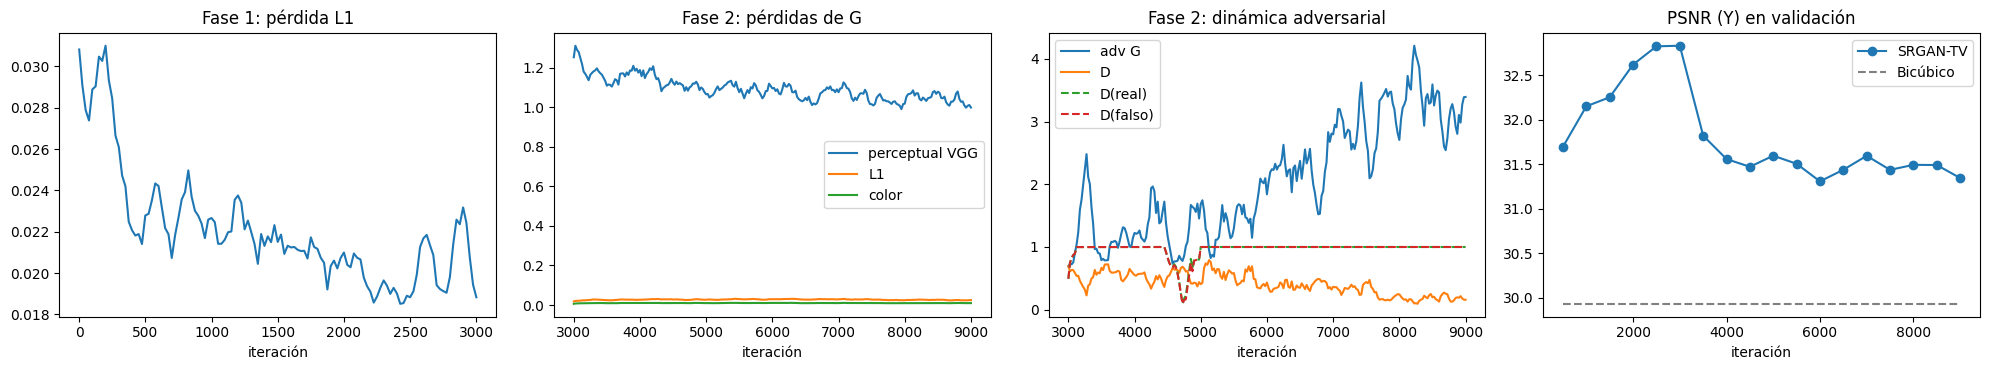

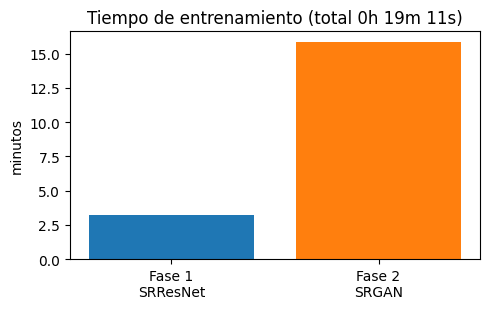

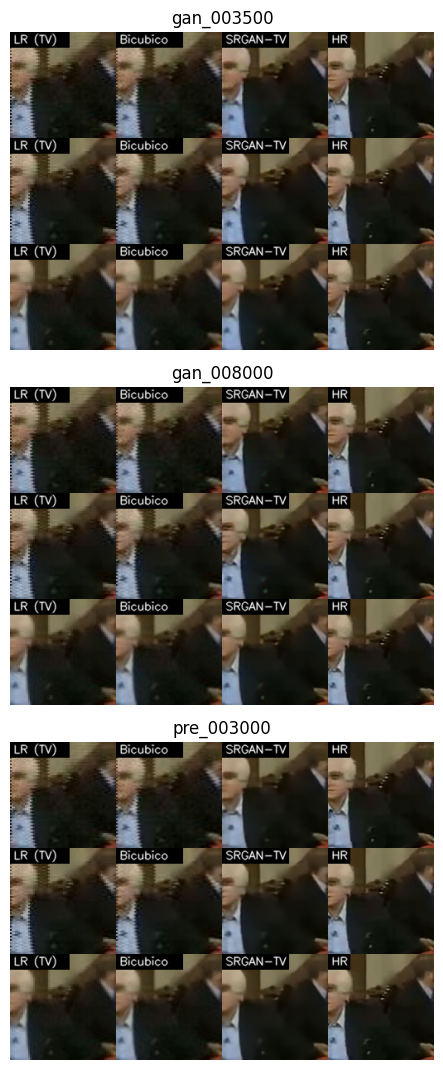

In [10]:
# ---- Curvas de entrenamiento (evidencia)
L, V = pd.DataFrame(log), pd.DataFrame(vlog)
sm = lambda s: s.rolling(5, min_periods=1).mean()
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
pre, gan = L[L.phase == "pre"], L[L.phase == "gan"]
ax[0].plot(pre.iter, sm(pre.l_pix)); ax[0].set_title("Fase 1: pérdida L1")
if len(gan):
    for c, n in [("l_perc", "perceptual VGG"), ("l_pix", "L1"), ("l_color", "color")]: ax[1].plot(gan.iter, sm(gan[c]), label=n)
    ax[1].legend(); ax[1].set_title("Fase 2: pérdidas de G")
    ax[2].plot(gan.iter, sm(gan.l_adv), label="adv G"); ax[2].plot(gan.iter, sm(gan.l_d), label="D")
    ax[2].plot(gan.iter, sm(gan.d_real), "--", label="D(real)"); ax[2].plot(gan.iter, sm(gan.d_fake), "--", label="D(falso)")
    ax[2].legend(); ax[2].set_title("Fase 2: dinámica adversarial")
ax[3].plot(V.iter, V.psnr, "o-", label="SRGAN-TV"); ax[3].plot(V.iter, V.psnr_bic, "--", c="gray", label="Bicúbico")
ax[3].set_title("PSNR (Y) en validación"); ax[3].legend()
for a in ax: a.set_xlabel("iteración")
plt.tight_layout(); plt.savefig(f"{OUT}/plots/curvas_entrenamiento.png", dpi=140); plt.show()

fig, ax = plt.subplots(figsize=(5, 3.2))
ph = STATS["fases"]; ax.bar(["Fase 1\nSRResNet", "Fase 2\nSRGAN"], [ph["fase1_srresnet"]["segundos"] / 60, ph["fase2_srgan"]["segundos"] / 60], color=["C0", "C1"])
ax.set_ylabel("minutos"); ax.set_title(f"Tiempo de entrenamiento (total {hms(T_TOTAL)})")
plt.tight_layout(); plt.savefig(f"{OUT}/plots/tiempo_entrenamiento.png", dpi=140); plt.show()

# ---- Evolución de las muestras
files = sorted(Path(f"{OUT}/samples").glob("*.png"))
pick = [files[0], files[len(files) // 2], files[-1]] if len(files) >= 3 else files
fig, ax = plt.subplots(len(pick), 1, figsize=(12, 3.6 * len(pick)))
for a, f in zip(np.atleast_1d(ax), pick):
    a.imshow(cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)); a.axis("off"); a.set_title(f.stem)
plt.tight_layout(); plt.savefig(f"{OUT}/plots/evolucion_muestras.png", dpi=110); plt.show()

## 4. SCRIPT DE OBTENCIÓN DE RESULTADOS

Procesa **el clip completo** con el generador entrenado y produce:
1. `video_mejorado_xN.mp4` (con el audio original),
2. `video_bicubico_xN.mp4` (misma resolución, interpolación clásica, para comparar),
3. `video_comparacion.mp4` (pantalla dividida: original | SRGAN-TV),
4. capturas *antes → después* con zoom,
5. tabla de calidad *antes → después* (resolución, nitidez, bloques y ruido).

In [11]:
G.eval()
RES = f"{OUT}/resultados"; os.makedirs(RES, exist_ok=True)
H1, W1 = H0, W0                                     # tamaño del clip (si no hubo submuestreo de tamaño)
cap = cv2.VideoCapture(CLIP); W1, H1 = int(cap.get(3)), int(cap.get(4)); cap.release()
WO, HO = W1 * SCALE, H1 * SCALE

class FFWriter:
    def __init__(s, path, W, H):
        s.p = subprocess.Popen(["ffmpeg", "-y", "-v", "error", "-f", "rawvideo", "-pix_fmt", "rgb24", "-s", f"{W}x{H}",
            "-r", INFO["fps_str"], "-i", "-", "-i", CLIP, "-map", "0:v", "-map", "1:a?", "-c:v", "libx264",
            "-preset", "medium", "-crf", "14", "-pix_fmt", "yuv420p", "-c:a", "copy", "-shortest", path], stdin=subprocess.PIPE)
    def write(s, a): s.p.stdin.write(np.ascontiguousarray(a).tobytes())
    def close(s): s.p.stdin.close(); s.p.wait()

def sharpness(rgb): return float(cv2.Laplacian(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var())
def blockiness(rgb, b=8):
    g = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32); d = np.abs(np.diff(g, axis=1)); c = np.arange(d.shape[1])
    return float(d[:, c % b == b - 1].mean() / (d[:, c % b != b - 1].mean() + 1e-6))
def noise_sigma(rgb):                                  # estimador de ruido de Immerkaer
    g = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
    return float(np.sqrt(np.pi / 2) / (6 * (g.shape[0] - 2) * (g.shape[1] - 2)) * np.abs(cv2.filter2D(g, -1, k)).sum())
def flicker(a, b): return float(np.abs(cv2.cvtColor(a, cv2.COLOR_RGB2GRAY).astype(np.float32) - cv2.cvtColor(b, cv2.COLOR_RGB2GRAY)).mean())

@torch.no_grad()
def enhance(rgb_u8):
    x = torch.from_numpy(rgb_u8.transpose(2, 0, 1).copy()).unsqueeze(0).to(dev).float() / 255
    with torch.autocast(dev.type, torch.float16, enabled=AMP): y = G(x)
    return (y[0].float().clamp(0, 1).permute(1, 2, 0).cpu().numpy() * 255 + .5).astype(np.uint8)

w_sr = FFWriter(f"{RES}/video_mejorado_x{SCALE}.mp4", WO, HO)
w_bic = FFWriter(f"{RES}/video_bicubico_x{SCALE}.mp4", WO, HO)
w_cmp = FFWriter(f"{RES}/video_comparacion.mp4", WO, HO)
n_frames = int(cv2.VideoCapture(CLIP).get(cv2.CAP_PROP_FRAME_COUNT))
snap_idx = set(np.linspace(int(.05 * n_frames), int(.95 * n_frames), 5).astype(int).tolist())
M = {"bic": [], "sr": []}; snaps = {}; prev = {"bic": None, "sr": None}; FL = {"bic": [], "sr": []}
cap = cv2.VideoCapture(CLIP); t_proc = time.perf_counter(); i = 0
for _ in tqdm(range(n_frames), desc="Mejorando el video"):
    ok, f = cap.read()
    if not ok: break
    src = cv2.cvtColor(f, cv2.COLOR_BGR2RGB)
    sr = enhance(src); bic = cv2.resize(src, (WO, HO), interpolation=cv2.INTER_CUBIC)
    w_sr.write(sr); w_bic.write(bic)
    cmp_ = np.concatenate([bic[:, :WO // 2], sr[:, WO // 2:]], 1); cmp_[:, WO // 2 - 1:WO // 2 + 1] = 255
    w_cmp.write(label(label(cmp_, "Original (bicubico)"), "SRGAN-TV", WO // 2 + 4))
    if i % 5 == 0:
        for k, im in (("bic", bic), ("sr", sr)):
            M[k].append((sharpness(im), blockiness(im), noise_sigma(im)))
    for k, im in (("bic", bic), ("sr", sr)):
        if prev[k] is not None: FL[k].append(flicker(prev[k], im))
        prev[k] = im
    if i in snap_idx: snaps[i] = (src, bic, sr)
    i += 1
cap.release()
for w in (w_sr, w_bic, w_cmp): w.close()
T_INFER = time.perf_counter() - t_proc
print(f"{i} frames procesados en {hms(T_INFER)} ({i / T_INFER:.1f} fps)")

Mejorando el video:   0%|          | 0/1950 [00:00<?, ?it/s]

1950 frames procesados en 0h 03m 48s (8.6 fps)


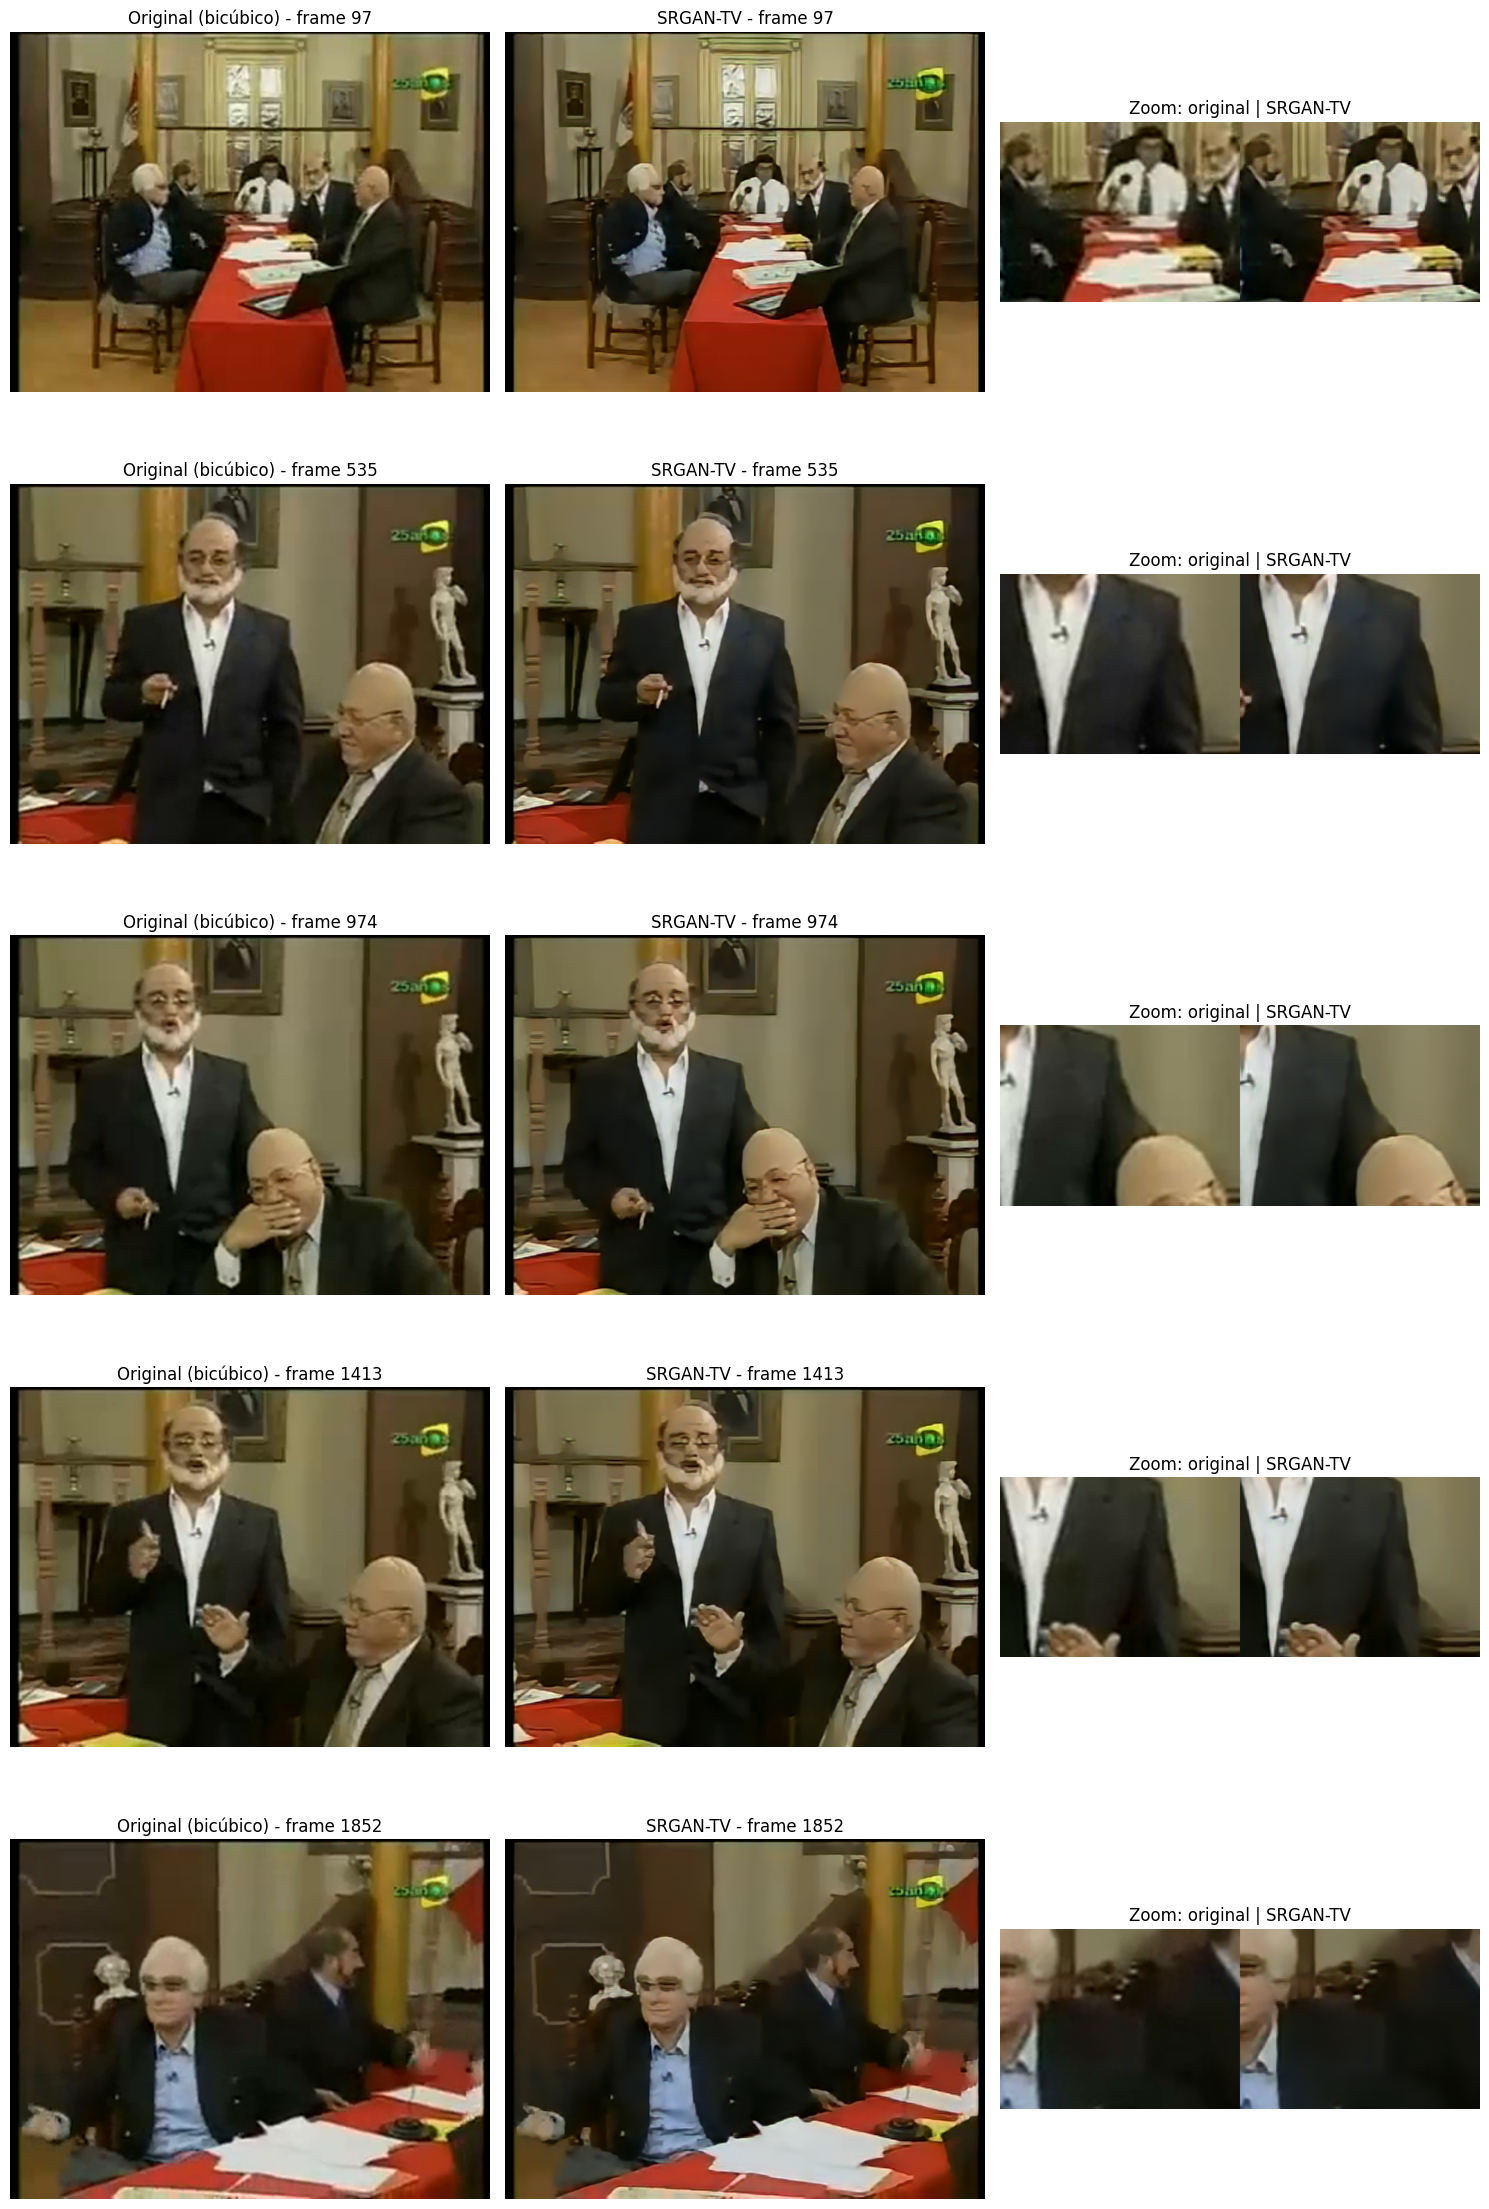

In [12]:
# ---- Capturas "antes -> después" con zoom
fig, axes = plt.subplots(len(snaps), 3, figsize=(15, 4.6 * len(snaps)))
axes = np.atleast_2d(axes)
for r, (idx, (src, bic, sr)) in enumerate(sorted(snaps.items())):
    h, w = sr.shape[:2]; ch, cw = h // 3, w // 3; y, x = (h - ch) // 2, (w - cw) // 2
    for c, (im, t) in enumerate([(bic, "Original (bicúbico)"), (sr, "SRGAN-TV"), (None, "Zoom: original | SRGAN-TV")]):
        a = axes[r, c]
        if c < 2: a.imshow(im); a.set_title(f"{t} - frame {idx}")
        else:
            a.imshow(np.concatenate([cv2.resize(bic[y:y + ch, x:x + cw], (cw * 2, ch * 2), interpolation=cv2.INTER_NEAREST),
                                     cv2.resize(sr[y:y + ch, x:x + cw], (cw * 2, ch * 2), interpolation=cv2.INTER_NEAREST)], 1)); a.set_title(t)
        a.axis("off")
    cv2.imwrite(f"{RES}/captura_{idx:05d}.png", cv2.cvtColor(np.concatenate([bic, sr], 1), cv2.COLOR_RGB2BGR))
plt.tight_layout(); plt.savefig(f"{RES}/antes_despues.png", dpi=110); plt.show()

                           característica antes (original)   después (SRGAN-TV)
                               Resolución          320x240              640x480
                        Píxeles por frame            76800               307200
                             Duración (s)             65.0                 65.0
                                      FPS             30.0                 30.0
Nitidez (var. Laplaciano, bicúbico vs SR)            44.63                248.8
  Bloques de compresión (1 = sin bloques)            1.081                1.028
                   Ruido estimado (sigma)            0.267                3.144
    Parpadeo temporal (dif. entre frames)            2.422                2.479
                  Tiempo de procesamiento                - 0h 03m 48s (8.6 fps)

Nota: 'antes' = el original agrandado con bicúbico a la misma resolución, para comparar justamente.
Mayor nitidez no siempre es mejor (el ruido también aumenta el Laplaciano): interpreta junto con bl

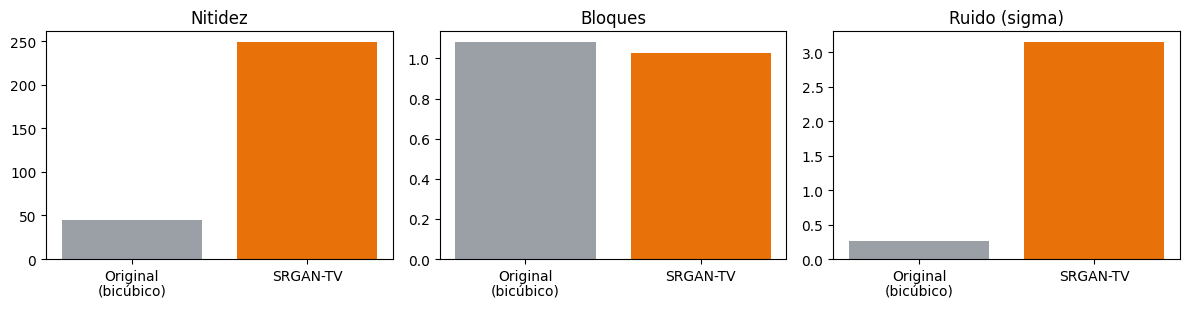

In [13]:
# ---- Tabla de calidad: cómo estaba -> cómo quedó
mb, ms = np.array(M["bic"]).mean(0), np.array(M["sr"]).mean(0)
INFO_SR = probe(f"{RES}/video_mejorado_x{SCALE}.mp4")
tabla = pd.DataFrame([
    {"característica": "Resolución", "antes (original)": f"{W1}x{H1}", "después (SRGAN-TV)": f"{WO}x{HO}"},
    {"característica": "Píxeles por frame", "antes (original)": W1 * H1, "después (SRGAN-TV)": WO * HO},
    {"característica": "Duración (s)", "antes (original)": round(INFO["duration"], 1), "después (SRGAN-TV)": round(INFO_SR["duration"], 1)},
    {"característica": "FPS", "antes (original)": round(INFO["fps"], 2), "después (SRGAN-TV)": round(INFO_SR["fps"], 2)},
    {"característica": "Nitidez (var. Laplaciano, bicúbico vs SR)", "antes (original)": round(mb[0], 2), "después (SRGAN-TV)": round(ms[0], 2)},
    {"característica": "Bloques de compresión (1 = sin bloques)", "antes (original)": round(mb[1], 3), "después (SRGAN-TV)": round(ms[1], 3)},
    {"característica": "Ruido estimado (sigma)", "antes (original)": round(mb[2], 3), "después (SRGAN-TV)": round(ms[2], 3)},
    {"característica": "Parpadeo temporal (dif. entre frames)", "antes (original)": round(np.mean(FL["bic"]), 3), "después (SRGAN-TV)": round(np.mean(FL["sr"]), 3)},
    {"característica": "Tiempo de procesamiento", "antes (original)": "-", "después (SRGAN-TV)": f"{hms(T_INFER)} ({i / T_INFER:.1f} fps)"},
])
tabla.to_csv(f"{RES}/tabla_antes_despues.csv", index=False)
md_lines = ["| " + " | ".join(tabla.columns) + " |", "|---|---|---|"] + ["| " + " | ".join(str(v) for v in r) + " |" for r in tabla.values]
open(f"{RES}/tabla_antes_despues.md", "w", encoding="utf-8").write("\n".join(md_lines))
print(tabla.to_string(index=False))
print("\nNota: 'antes' = el original agrandado con bicúbico a la misma resolución, para comparar justamente.")
print("Mayor nitidez no siempre es mejor (el ruido también aumenta el Laplaciano): interpreta junto con bloques y ruido.")
json.dump({"tiempo_inferencia_s": round(T_INFER, 1), "frames": i, "pesos_usados": "G_final_srgan.pth"},
          open(f"{RES}/resumen_resultados.json", "w"), indent=2)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, (j, n) in zip(ax, enumerate(["Nitidez", "Bloques", "Ruido (sigma)"])):
    a.bar(["Original\n(bicúbico)", "SRGAN-TV"], [mb[j], ms[j]], color=["#9aa0a6", "#e8710a"]); a.set_title(n)
plt.tight_layout(); plt.savefig(f"{RES}/metricas_antes_despues.png", dpi=140); plt.show()

In [14]:
# ---- Ver el video comparativo y descargar las evidencias
try:
    from IPython.display import Video, display
    display(Video(f"{RES}/video_comparacion.mp4", embed=True, width=640))
except Exception as e:
    print("No se pudo incrustar el video:", e)

zip_path = shutil.make_archive(OUT.rstrip("/") + "_evidencias", "zip", OUT)
print("Evidencias empaquetadas:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.0f} MB)")
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive"); shutil.copytree(OUT, DRIVE_DIR, dirs_exist_ok=True); print("Copiado a", DRIVE_DIR)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass

Evidencias empaquetadas: /content/srgan_tv_evidencias.zip (128 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Presentación: cambios, ajustes y mejoras (7 min)

1. **Problema:** videos de TV peruana 2000-2010 (SD, entrelazados, ruido analógico, compresión doble).
2. **SRGAN base:** generador residual + discriminador + pérdida perceptual VGG.
3. **Datos (autosupervisado):** solo hay un video antiguo → sus frames son la HR y se degradan para crear la LR.
4. **Degradación de TV** en vez de bicúbico (desenfoque, croma, entrelazado, ruido, doble JPEG).
5. **Cambios al modelo:** sin BatchNorm, residual sobre bicúbico, L1, VGG pre-ReLU, RaGAN + Spectral Norm, pérdida de color.
6. **Entrenamiento en 2 fases** (SRResNet → SRGAN) con evidencias: pérdidas, PSNR/SSIM, **tiempo y pesos**.
7. **Resultados:** video antes → después, zoom y tabla de calidad.
8. **Limitaciones:** el modelo solo aprende de un video; no inventa detalle que nunca vio → trabajo futuro: más datos HD (DIV2K), entrada multi-frame para reducir parpadeo.

In [15]:
from google.colab import drive
import shutil
drive.mount("/content/drive")
shutil.copytree("/content/srgan_tv", "/content/drive/MyDrive/PC3_SRGAN/evidencias", dirs_exist_ok=True)
shutil.copy("/content/srgan_tv_evidencias.zip", "/content/drive/MyDrive/PC3_SRGAN/")
print("Copiado a Drive")


Mounted at /content/drive
Copiado a Drive
